# MSDS 451 — Term Project Checkpoint B
## Historical Data Preparation for the Machine Learning–Enhanced Adaptive Momentum ETF

This notebook prepares the six exchange-traded products from Checkpoint A: **SPY, XLF, XLV, IEF, GLD, and SHY**. It checks the available historical coverage, uses adjusted price series to estimate distribution-reinvested total-return proxies, calculates daily log returns and preliminary risk statistics, and previews the previously proposed monthly momentum signals.

**Scope:** Checkpoint B data collection and preliminary findings. **No actual fund backtest, ML accuracy, or Monte Carlo results are claimed here.** Results appear only after this notebook downloads and analyzes real market data.

**Reproducible archived run:** uses the actual saved Yahoo Finance daily histories downloaded on October 26, 2026. Set `DOWNLOAD_FRESH=True` to retrieve a new data vintage.


### 1. Install dependencies
Run the optional installation command **once** in a Jupyter cell if imports fail:

`%pip install -r requirements.txt`

Then restart the kernel if Jupyter asks you to. The local `requirements.txt` is included with this notebook.

In [1]:
from pathlib import Path
from datetime import date, datetime, timedelta, timezone
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import yfinance as yf
except ImportError:
    yf = None  # Optional when using saved CSVs (DOWNLOAD_FRESH=False)

TICKERS = ['SPY', 'XLF', 'XLV', 'IEF', 'GLD', 'SHY']
SELECTION = ['SPY', 'XLF', 'XLV', 'IEF', 'GLD']
DEFENSIVE = 'SHY'
START_DATE = '1993-01-01'  # intentionally earlier than all six launches
END_EXCLUSIVE = '2026-10-27'  # as archived; adjust only when refreshing Yahoo data
# Change to False to reproduce results from the saved data/raw CSV files.
DOWNLOAD_FRESH = False

ROOT = Path.cwd()
RAW = ROOT / 'data' / 'raw'
PROCESSED = ROOT / 'data' / 'processed'
TABLES = ROOT / 'outputs' / 'tables'
FIGURES = ROOT / 'outputs' / 'figures'
for folder in [RAW, PROCESSED, TABLES, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)
print('Window requested:', START_DATE, 'through last available trading day before', END_EXCLUSIVE)
print('Project folder is ready.')

Window requested: 1993-01-01 through last available trading day before 2026-10-27
Project folder is ready.


### 2. Download daily Yahoo Finance history
We request daily observations separately for each ticker. `auto_adjust=False` retains both the quoted close and **Adj Close**. Adj Close is used as a *proxy* for a reinvested-distribution total-return price series. This is an approximation, not a separately audited total-return index. We also archive dividends and stock-split data for review.

If Yahoo Finance is unavailable, switch `DOWNLOAD_FRESH=False` **only after** these raw files have already been saved; otherwise the notebook stops rather than inventing prices.

In [2]:
frames = {}
metadata = []
for ticker in TICKERS:
    raw_path = RAW / f'{ticker}_daily_history.csv'
    if DOWNLOAD_FRESH:
        try:
            hist = yf.Ticker(ticker).history(
                start=START_DATE, end=END_EXCLUSIVE, interval='1d',
                auto_adjust=False, actions=True, raise_errors=True)
        except Exception as exc:
            raise RuntimeError(f'Could not download {ticker}: {exc}. If archived files exist, set DOWNLOAD_FRESH=False.') from exc
        if hist.empty or 'Adj Close' not in hist.columns:
            raise RuntimeError(f'{ticker} did not return an adjusted-close series; do not substitute Close silently.')
        hist = hist.copy()
        hist.index = pd.to_datetime(hist.index)
        hist.index = hist.index.tz_localize(None) if hist.index.tz is not None else hist.index
        hist.index = hist.index.normalize()
        hist.index.name = 'Date'
        hist = hist.loc[~hist.index.duplicated(keep='last')].sort_index()
        keep = [c for c in ['Open','High','Low','Close','Adj Close','Volume','Dividends','Stock Splits'] if c in hist.columns]
        hist = hist[keep]
        hist.to_csv(raw_path, index=True, float_format='%.10f')
    else:
        if not raw_path.exists():
            raise FileNotFoundError(f'Missing {raw_path}. Download the data first.')
        hist = pd.read_csv(raw_path, index_col='Date', parse_dates=['Date']).sort_index()
        if 'Adj Close' not in hist.columns:
            raise ValueError(f'Adj Close missing from archived {raw_path}.')
    hist['Adj Close'] = pd.to_numeric(hist['Adj Close'], errors='coerce')
    valid = hist['Adj Close'].dropna()
    valid = valid[valid > 0]
    if len(valid) < 252 * 5:
        raise ValueError(f'Insufficient history for {ticker}: {len(valid)} valid days (< five trading years).')
    frames[ticker] = hist
    metadata.append(dict(Ticker=ticker, FirstPriceDate=valid.index.min().date().isoformat(),
                         LastPriceDate=valid.index.max().date().isoformat(),
                         ValidAdjustedCloses=len(valid),
                         MissingOrInvalidAdjClose=int(len(hist) - len(valid)),
                         DividendsRows=int((pd.to_numeric(hist.get('Dividends', pd.Series(0., index=hist.index)),errors='coerce').fillna(0) != 0).sum()),
                         Source='Yahoo Finance via yfinance'))
coverage = pd.DataFrame(metadata)
coverage.to_csv(TABLES / 'data_coverage_by_ticker.csv', index=False)
display(coverage)

,Ticker,FirstPriceDate,LastPriceDate,ValidAdjustedCloses,MissingOrInvalidAdjClose,DividendsRows,Source
0,SPY,1993-01-29,2026-10-26,8493,0,136,Yahoo Finance via yfinance
1,XLF,1998-12-22,2026-10-26,7003,0,111,Yahoo Finance via yfinance
2,XLV,1998-12-22,2026-10-26,7003,0,106,Yahoo Finance via yfinance
3,IEF,2002-07-30,2026-10-26,6100,0,291,Yahoo Finance via yfinance
4,GLD,2004-11-18,2026-10-26,5518,0,0,Yahoo Finance via yfinance
5,SHY,2002-07-30,2026-10-26,6100,0,290,Yahoo Finance via yfinance


### 3. Establish a common daily sample and calculate returns
Using **the same trading dates for all six products** avoids comparing unmatched samples. The common series cannot begin before GLD starts trading in November 2004. The monthly 200-day moving-average rule requires an additional warm-up window.

Daily log return in percent: $r_t = 100\ln(P_t^{adj}/P_{t-1}^{adj})$. For annualized volatility, multiply the sample standard deviation of unscaled daily log returns by $\sqrt{252}$.

In [3]:
adj = pd.DataFrame({ticker: frames[ticker]['Adj Close'] for ticker in TICKERS}).sort_index()
adj = adj.where(adj > 0)
first_common = max(adj[t].first_valid_index() for t in TICKERS)
last_common = min(adj[t].last_valid_index() for t in TICKERS)
prices = adj.loc[first_common:last_common].dropna(how='any')
if len(prices) < 252*5:
    raise ValueError('Fewer than five years of overlapping history across all instruments.')
# Missing rows inside the overlapping window are excluded, never forward-filled for returns.
log_returns_pct = 100 * np.log(prices / prices.shift(1)).iloc[1:]
simple_returns = prices.pct_change().iloc[1:]
assert np.isfinite(log_returns_pct.to_numpy()).all()
prices.to_csv(PROCESSED / 'adjusted_prices_aligned.csv', index_label='Date', float_format='%.10f')
log_returns_pct.to_csv(PROCESSED / 'daily_log_returns_percent.csv', index_label='Date', float_format='%.10f')
simple_returns.to_csv(PROCESSED / 'daily_simple_returns.csv', index_label='Date', float_format='%.10f')

print('Common adjusted-price window:', prices.index.min().date(), 'to', prices.index.max().date())
print('Common daily prices:', len(prices), '| usable log returns:', len(log_returns_pct))
print('First date with 200 daily price observations:', prices.index[199].date())

Common adjusted-price window: 2004-11-18 to 2026-10-26
Common daily prices: 5518 | usable log returns: 5517
First date with 200 daily price observations: 2005-09-02


### 4. Initial exploratory findings
The table measures each product over the **common sample**, not over different ticker-specific windows. CAGR is computed from the adjusted-price growth proxy; annualized volatility is based on daily log-return standard deviation. Drawdown is the largest observed peak-to-trough decline in adjusted-price wealth. These are historical summaries, **not the returns of the proposed actively managed fund**.

In [4]:
stats = []
for ticker in TICKERS:
    p = prices[ticker]
    r_log = log_returns_pct[ticker] / 100.0
    n_days = len(p) - 1
    cagr = (float(p.iloc[-1] / p.iloc[0]) ** (252.0 / n_days) - 1) * 100
    annual_vol = float(r_log.std(ddof=1) * np.sqrt(252) * 100)
    max_dd = float((p / p.cummax() - 1).min() * 100)
    stats.append({'Ticker': ticker, 'Start': str(p.index[0].date()), 'End': str(p.index[-1].date()),
                  'CAGR_AdjustedProxy_pct': cagr, 'AnnualizedVolatility_pct': annual_vol,
                  'MaxDrawdown_pct': max_dd,
                  'TotalAdjustedPriceGrowth_pct': (float(p.iloc[-1]/p.iloc[0])-1)*100})
summary = pd.DataFrame(stats).sort_values('Ticker')
summary.to_csv(TABLES / 'preliminary_return_risk_summary.csv', index=False, float_format='%.6f')
display(summary.round(2))
correlation = log_returns_pct.corr()
correlation.to_csv(TABLES / 'daily_log_return_correlations.csv', float_format='%.6f')
display(correlation.round(2))

,Ticker,Start,End,CAGR_AdjustedProxy_pct,AnnualizedVolatility_pct,MaxDrawdown_pct,TotalAdjustedPriceGrowth_pct
4,GLD,2004-11-18,2026-10-26,10.14,18.30,-45.56,728.80
3,IEF,2004-11-18,2026-10-26,3.04,6.73,-23.92,92.49
5,SHY,2004-11-18,2026-10-26,1.95,1.49,-5.71,52.47
0,SPY,2004-11-18,2026-10-26,10.89,18.83,-55.19,862.15
1,XLF,2004-11-18,2026-10-26,6.03,28.71,-82.69,260.55
2,XLV,2004-11-18,2026-10-26,10.58,16.67,-39.17,803.35


,SPY,XLF,XLV,IEF,GLD,SHY
SPY,1.00,0.84,0.79,-0.28,0.07,-0.22
XLF,0.84,1.00,0.63,-0.31,-0.03,-0.26
XLV,0.79,0.63,1.00,-0.20,0.03,-0.12
IEF,-0.28,-0.31,-0.20,1.00,0.21,0.76
GLD,0.07,-0.03,0.03,0.21,1.00,0.21
SHY,-0.22,-0.26,-0.12,0.76,0.21,1.00


### 5. Visual checks: cumulative wealth, correlations, and drawdowns
These figures are exploratory evidence for Checkpoint B; they are **not yet a strategy backtest**.

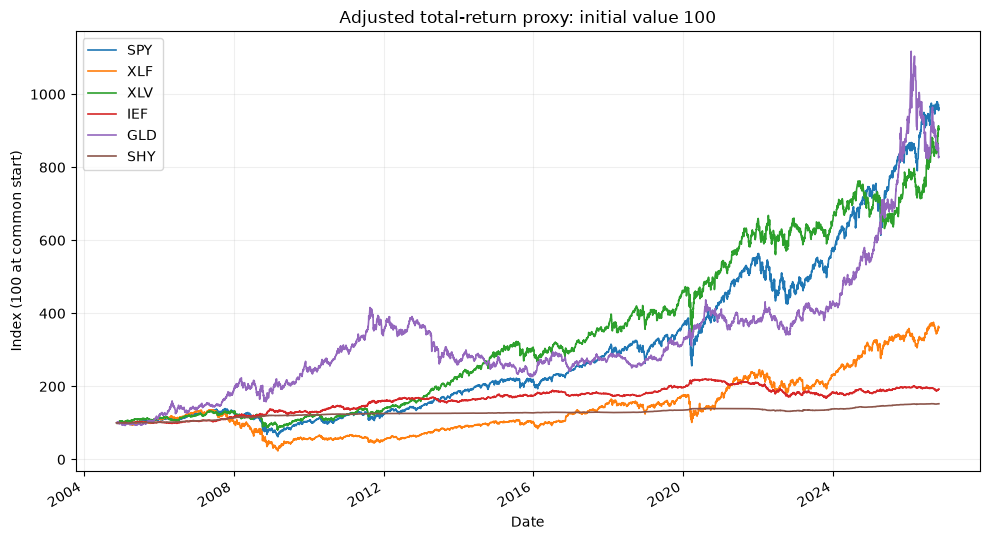

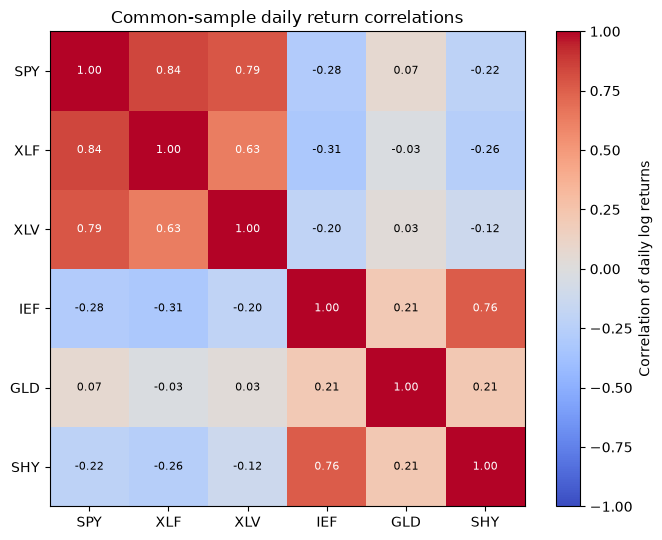

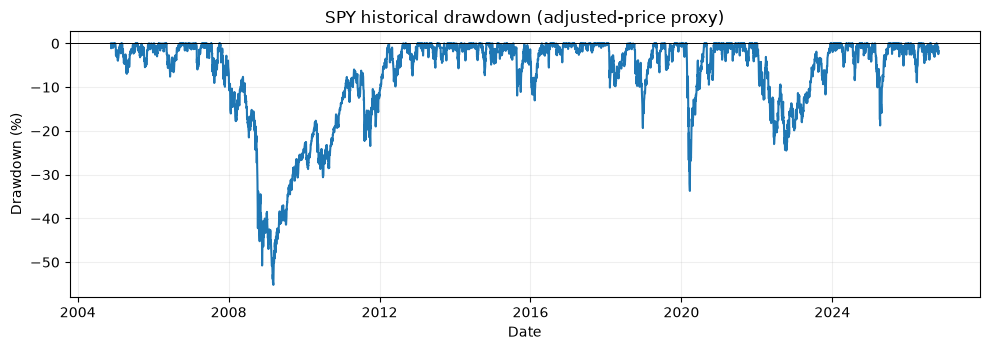

In [5]:
rebased = prices / prices.iloc[0] * 100
ax = rebased.plot(figsize=(10, 5.5), linewidth=1.2, title='Adjusted total-return proxy: initial value 100')
ax.set_xlabel('Date'); ax.set_ylabel('Index (100 at common start)'); ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(FIGURES/'adjusted_total_return_proxy.png', dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(correlation.to_numpy(), vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(TICKERS)), TICKERS); ax.set_yticks(range(len(TICKERS)), TICKERS)
for i in range(len(TICKERS)):
    for j in range(len(TICKERS)):
        ax.text(j, i, f'{correlation.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(correlation.iloc[i,j]) > .55 else 'black')
fig.colorbar(im, ax=ax, label='Correlation of daily log returns')
ax.set_title('Common-sample daily return correlations')
fig.tight_layout(); fig.savefig(FIGURES/'daily_return_correlations.png', dpi=160); plt.show()

spy_dd = (prices['SPY'] / prices['SPY'].cummax() - 1) * 100
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(spy_dd.index, spy_dd.values)
ax.axhline(0, color='black', linewidth=.7)
ax.set(title='SPY historical drawdown (adjusted-price proxy)', ylabel='Drawdown (%)', xlabel='Date')
ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(FIGURES/'SPY_historical_drawdown.png', dpi=160); plt.show()

### 6. Preview monthly momentum and trend inputs
This is a **signal availability check**, not a performance backtest. At each observed month-end close we compute the past 126-trading-day total-return momentum and the 200-day simple moving average. The ranking uses five assets and SHY is the fallback. **Any actual order would be placed no earlier than the next trading session**; results here do not assume a trade at the signal-generating close.

The latest observed calendar month is excluded from completed month-end signals unless its end-of-month data have been confirmed. This archived run ends October 26, 2026; October is **not** a completed month.


In [6]:
momentum_126 = prices / prices.shift(126) - 1
sma_200 = prices.rolling(200, min_periods=200).mean()
# Do not treat an unfinished calendar month as a completed month-end.
month_ends_all = prices.groupby(prices.index.to_period('M')).tail(1).index
month_ends = month_ends_all[month_ends_all.to_period('M') < prices.index[-1].to_period('M')]
print('Latest month excluded as incomplete:', prices.index[-1].to_period('M'))
rows=[]
for dt in month_ends:
    if pd.isna(sma_200.at[dt, 'SPY']):
        continue
    eligible = [t for t in SELECTION
                if bool(prices.at[dt,t] > sma_200.at[dt,t]) and
                pd.notna(momentum_126.at[dt,t]) and momentum_126.at[dt,t] > 0]
    selected = sorted(eligible, key=lambda t: (-momentum_126.at[dt,t], t))[:2]
    weights = {ticker: (0.5 if ticker in selected else 0.0) for ticker in SELECTION}
    weights[DEFENSIVE] = 1.0 - 0.5 * len(selected)
    assert abs(sum(weights.values()) - 1) < 1e-12
    rows.append({'SignalDate':dt.date().isoformat(), 'Selected1': selected[0] if len(selected)>=1 else '',
                 'Selected2':selected[1] if len(selected)>=2 else '', 'EligibleCount':len(eligible),
                 **{f'TargetWeight_{t}':weights[t] for t in TICKERS}})
signal_preview = pd.DataFrame(rows)
signal_preview.to_csv(TABLES / 'monthly_signal_preview_NOT_BACKTEST.csv',index=False)
print('Month-end signals with complete 200-day window:', len(signal_preview))
display(signal_preview.tail(6))

Latest month excluded as incomplete: 2026-10
Month-end signals with complete 200-day window: 253


,SignalDate,Selected1,Selected2,EligibleCount,TargetWeight_SPY,TargetWeight_XLF,TargetWeight_XLV,TargetWeight_IEF,TargetWeight_GLD,TargetWeight_SHY
247,2026-04-30,GLD,SPY,3,0.5,0.0,0.0,0.0,0.5,0.0
248,2026-05-29,SPY,GLD,2,0.5,0.0,0.0,0.0,0.5,0.0
249,2026-06-30,SPY,XLV,2,0.5,0.0,0.5,0.0,0.0,0.0
250,2026-07-31,SPY,XLF,3,0.5,0.5,0.0,0.0,0.0,0.0
251,2026-08-31,XLF,SPY,3,0.5,0.5,0.0,0.0,0.0,0.0
252,2026-09-30,SPY,XLV,3,0.5,0.0,0.5,0.0,0.0,0.0


### 7. Sensitivity check: different momentum lookback windows
All lookback windows use completed month-end dates. The 252-day window has 251 usable months, compared with 253 months for the shorter windows. These are signal comparisons, not realized investment returns.

In [7]:
sensitivity_rows = []
for lookback in [63, 126, 252]:
    rolling_momentum = prices / prices.shift(lookback) - 1
    n_none = n_one = n_two = 0
    total_shy = 0.0
    n_months = 0
    for dt in month_ends:
        if any(pd.isna(sma_200.at[dt, t]) or pd.isna(rolling_momentum.at[dt, t]) for t in SELECTION):
            continue
        eligible = [t for t in SELECTION
                    if prices.at[dt, t] > sma_200.at[dt, t] and rolling_momentum.at[dt, t] > 0]
        selected_count = min(2, len(eligible))
        n_months += 1
        n_none += selected_count == 0
        n_one += selected_count == 1
        n_two += selected_count == 2
        total_shy += 1.0 - 0.5*selected_count
    if n_months == 0:
        raise ValueError('No complete signal dates available for sensitivity calculation.')
    sensitivity_rows.append({'MomentumLookbackDays': lookback, 'MonthsWithCompleteSignals': n_months,
                             'MonthsZeroSelections': int(n_none), 'MonthsOneSelection': int(n_one),
                             'MonthsTwoSelections': int(n_two),
                             'MeanSHYTargetWeight_NotRealized': total_shy/n_months})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(TABLES / 'signal_window_sensitivity_NOT_BACKTEST.csv', index=False)
display(sensitivity.round(3))

,MomentumLookbackDays,MonthsWithCompleteSignals,MonthsZeroSelections,MonthsOneSelection,MonthsTwoSelections,MeanSHYTargetWeight_NotRealized
0,63,253,13,30,210,0.111
1,126,253,7,18,228,0.063
2,252,251,8,23,220,0.078


### 8. Data provenance and next work
In the next checkpoint, I plan to backtest the monthly trading strategy and compare its results with SPY buy-and-hold. I will also account for trading costs. Later, I will test whether machine learning improves risk-adjusted performance. I will also check how the results change with different lookback windows and cost assumptions.


In [8]:
metadata = {
  'notebook_run_utc': datetime.now(timezone.utc).isoformat(),
  'archived_data_download_date': '2026-10-26',
  'source': 'Yahoo Finance via yfinance',
  'download_fresh_this_run': DOWNLOAD_FRESH,
  'requested_start_inclusive': START_DATE,
  'requested_end_exclusive': END_EXCLUSIVE,
  'tickers': TICKERS,
  'price_field': 'Adj Close',
  'returns_definition': '100 * natural log ratio of consecutive adjusted prices',
  'total_return_caveat': 'Adj Close is a dividend/split-adjusted proxy; not independently audited',
  'common_start': prices.index.min().date().isoformat(),
  'common_end': prices.index.max().date().isoformat(),
  'annualization_trading_days': 252,
  'market_history_claim': 'Observed historical adjusted prices; no strategy performance claimed',
  'versions': {'pandas':pd.__version__, 'numpy':np.__version__, 'yfinance':getattr(yf,'__version__','unknown')}
}
(PROCESSED / 'data_provenance.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print('1) outputs/tables/data_coverage_by_ticker.csv')
print('2) outputs/tables/preliminary_return_risk_summary.csv')
print('3) outputs/tables/daily_log_return_correlations.csv')
print('4) outputs/tables/monthly_signal_preview_NOT_BACKTEST.csv')
print('5) outputs/tables/signal_window_sensitivity_NOT_BACKTEST.csv')

1) outputs/tables/data_coverage_by_ticker.csv
2) outputs/tables/preliminary_return_risk_summary.csv
3) outputs/tables/daily_log_return_correlations.csv
4) outputs/tables/monthly_signal_preview_NOT_BACKTEST.csv
5) outputs/tables/signal_window_sensitivity_NOT_BACKTEST.csv
